In [1]:
# Importamos las librerías necesarias para realizar la regresión logística

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn import metrics
from sklearn import preprocessing
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [3]:
# Cargamos la base de datos drugs.csv
# Mostramos las primeras observaciones

df = pd.read_csv("drugs.csv")

df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [4]:
# Revisamos los nombres de las columnas y sus tipos de datos
# Identificamos las variables cualitativas que debemos transformar

print(df.columns)
print(df.dtypes)
print(df.shape)

Index(['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K', 'Drug'], dtype='object')
Age              int64
Sex             object
BP              object
Cholesterol     object
Na_to_K        float64
Drug            object
dtype: object
(200, 6)


In [5]:
# Convertimos las variables predictoras cualitativas a valores numéricos
# LabelEncoder asigna valores como 0, 1 y 2 a las categorías

le = preprocessing.LabelEncoder()

for columna in df.select_dtypes(include=['object', 'category']).columns:
    if columna != 'Drug':
        df[columna] = le.fit_transform(df[columna])

df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,0,0,0,25.355,drugY
1,47,1,1,0,13.093,drugC
2,47,1,1,0,10.114,drugC
3,28,0,2,0,7.798,drugX
4,61,0,1,0,18.043,drugY


In [6]:
# Identificamos la variable dependiente Drug
# Convertimos sus categorías a valores numéricos

le_drug = preprocessing.LabelEncoder()

df["Drug"] = le_drug.fit_transform(df["Drug"])

# Mostramos las categorías originales y sus códigos numéricos
print(dict(enumerate(le_drug.classes_)))

df.head()

{0: 'drugA', 1: 'drugB', 2: 'drugC', 3: 'drugX', 4: 'drugY'}


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,0,0,0,25.355,4
1,47,1,1,0,13.093,2
2,47,1,1,0,10.114,2
3,28,0,2,0,7.798,3
4,61,0,1,0,18.043,4


In [7]:
# Seleccionamos las características para el modelo
# X contiene las variables predictoras
# y contiene el tipo de medicamento que queremos predecir

feature_cols = df.drop(columns=["Drug"]).columns

X = df[feature_cols]
y = df.Drug

print(X.head())
print(y.head())

   Age  Sex  BP  Cholesterol  Na_to_K
0   23    0   0            0   25.355
1   47    1   1            0   13.093
2   47    1   1            0   10.114
3   28    0   2            0    7.798
4   61    0   1            0   18.043
0    4
1    2
2    2
3    3
4    4
Name: Drug, dtype: int64


In [8]:
# Dividimos la base en 80% para entrenamiento y 20% para prueba
# Conservamos las proporciones de las clases con stratify

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 1, stratify = y
)

In [9]:
# Estandarizamos las variables predictoras después de dividir la base
# Usamos los parámetros del conjunto de entrenamiento
# para evitar utilizar información del conjunto de prueba

scaler = preprocessing.StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
# Aplicamos regresión logística con el método sag
# Entrenamos el modelo con los datos de entrenamiento

model_sag = LogisticRegression(solver="sag", max_iter=5000)

clf_sag = model_sag.fit(X_train, y_train)

# Realizamos las predicciones
y_pred_sag = model_sag.predict(X_test)

# Mostramos los coeficientes del modelo
print("Intercepto (Beta0): ", clf_sag.intercept_)
print("Pesos (Betas): ", clf_sag.coef_)

print("------------------------------------------------------------------------------------------")

# Evaluamos la precisión del modelo
score_sag = model_sag.score(X_test, y_test)
print("Precisión global: ", score_sag)

print("------------------------------------------------------------------------------------------")

# Mostramos el reporte de clasificación
print(classification_report(y_test, y_pred_sag, target_names=le_drug.classes_, zero_division=0))

Intercepto (Beta0):  [-1.44355343 -1.45560895 -0.50915385  0.36666284  3.04165339]
Pesos (Betas):  [[-0.8845698   0.30476852 -2.07149277 -0.25005777 -1.31388694]
 [ 1.25747359 -0.2505192  -1.75745568 -0.01838913 -0.40816846]
 [-0.28356171  0.01174703  0.41627105 -1.21167409 -1.10859843]
 [-0.08099977 -0.1756989   2.74629771  1.36596599 -1.26389632]
 [-0.00834231  0.10970255  0.66637969  0.11415501  4.09455015]]
------------------------------------------------------------------------------------------
Precisión global:  0.925
------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         5
       drugB       1.00      1.00      1.00         3
       drugC       1.00      0.67      0.80         3
       drugX       0.85      1.00      0.92        11
       drugY       0.94      0.89      0.91        18

    accuracy                           0.93        4

In [11]:
# Aplicamos regresión logística con el método newton-cg
# Entrenamos el modelo y evaluamos sus resultados

model_newton = LogisticRegression(solver="newton-cg", max_iter=5000)

clf_newton = model_newton.fit(X_train, y_train)

y_pred_newton = model_newton.predict(X_test)

print("Intercepto (Beta0): ", clf_newton.intercept_)
print("Pesos (Betas): ", clf_newton.coef_)

print("------------------------------------------------------------------------------------------")

score_newton = model_newton.score(X_test, y_test)
print("Precisión global: ", score_newton)

print("------------------------------------------------------------------------------------------")

print(classification_report(y_test, y_pred_newton, target_names=le_drug.classes_, zero_division=0))

Intercepto (Beta0):  [-1.44365677 -1.45445916 -0.50901621  0.36602008  3.04111207]
Pesos (Betas):  [[-0.88482304  0.30505212 -2.0716274  -0.24989739 -1.31373018]
 [ 1.25716338 -0.250554   -1.75705303 -0.01848385 -0.40719038]
 [-0.2834889   0.01158628  0.41626682 -1.21154374 -1.10874217]
 [-0.0805135  -0.17575632  2.74629999  1.36603138 -1.26463506]
 [-0.00833795  0.10967192  0.66611362  0.11389359  4.09429779]]
------------------------------------------------------------------------------------------
Precisión global:  0.925
------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         5
       drugB       1.00      1.00      1.00         3
       drugC       1.00      0.67      0.80         3
       drugX       0.85      1.00      0.92        11
       drugY       0.94      0.89      0.91        18

    accuracy                           0.93        4

In [12]:
# Aplicamos regresión logística con el método saga
# Entrenamos el modelo y evaluamos sus resultados

model_saga = LogisticRegression(solver="saga", max_iter=5000)

clf_saga = model_saga.fit(X_train, y_train)

y_pred_saga = model_saga.predict(X_test)

print("Intercepto (Beta0): ", clf_saga.intercept_)
print("Pesos (Betas): ", clf_saga.coef_)

print("------------------------------------------------------------------------------------------")

score_saga = model_saga.score(X_test, y_test)
print("Precisión global: ", score_saga)

print("------------------------------------------------------------------------------------------")

print(classification_report(y_test, y_pred_saga, target_names=le_drug.classes_, zero_division=0))

Intercepto (Beta0):  [-1.4394857  -1.45104609 -0.51312162  0.363551    3.04010242]
Pesos (Betas):  [[-0.88423831  0.30493614 -2.06960077 -0.24954866 -1.31094094]
 [ 1.2564368  -0.25020442 -1.75576373 -0.01811443 -0.40494979]
 [-0.28346137  0.01153999  0.41516669 -1.21296019 -1.11135701]
 [-0.08048641 -0.17589981  2.74570984  1.36655099 -1.26683463]
 [-0.00825071  0.1096281   0.66448798  0.11407229  4.09408238]]
------------------------------------------------------------------------------------------
Precisión global:  0.925
------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         5
       drugB       1.00      1.00      1.00         3
       drugC       1.00      0.67      0.80         3
       drugX       0.85      1.00      0.92        11
       drugY       0.94      0.89      0.91        18

    accuracy                           0.93        4

In [13]:
# Aplicamos regresión logística con el método lbfgs
# Entrenamos el modelo y evaluamos sus resultados

model_lbfgs = LogisticRegression(solver="lbfgs", max_iter=5000)

clf_lbfgs = model_lbfgs.fit(X_train, y_train)

y_pred_lbfgs = model_lbfgs.predict(X_test)

print("Intercepto (Beta0): ", clf_lbfgs.intercept_)
print("Pesos (Betas): ", clf_lbfgs.coef_)

print("------------------------------------------------------------------------------------------")

score_lbfgs = model_lbfgs.score(X_test, y_test)
print("Precisión global: ", score_lbfgs)

print("------------------------------------------------------------------------------------------")

print(classification_report(y_test, y_pred_lbfgs, target_names=le_drug.classes_, zero_division=0))

Intercepto (Beta0):  [-1.44180576 -1.45113979 -0.52019496  0.37089642  3.04224409]
Pesos (Betas):  [[-0.88462162  0.30470481 -2.07113511 -0.24821055 -1.31256521]
 [ 1.25601984 -0.24996469 -1.75597209 -0.01658145 -0.40593907]
 [-0.2830712   0.01146558  0.41556536 -1.21709801 -1.11590327]
 [-0.0804389  -0.17601146  2.74467137  1.36637362 -1.25946094]
 [-0.00788811  0.10980577  0.66687047  0.11551639  4.09386849]]
------------------------------------------------------------------------------------------
Precisión global:  0.925
------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         5
       drugB       1.00      1.00      1.00         3
       drugC       1.00      0.67      0.80         3
       drugX       0.85      1.00      0.92        11
       drugY       0.94      0.89      0.91        18

    accuracy                           0.93        4

In [14]:
# Comparamos la precisión global de los cuatro métodos de optimización
# Mostramos los resultados en una tabla para identificar el mejor

resultados = pd.DataFrame({
    "Método": ["sag", "newton-cg", "saga", "lbfgs"],
    "Precisión": [score_sag, score_newton, score_saga, score_lbfgs]
})

resultados = resultados.sort_values(by="Precisión", ascending=False)

print(resultados)

      Método  Precisión
0        sag      0.925
1  newton-cg      0.925
2       saga      0.925
3      lbfgs      0.925


In [15]:
# Calculamos el F1-score macro de cada modelo
# Seleccionamos el mejor modelo según precisión y F1-score

from sklearn.metrics import f1_score

resultados["F1 Macro"] = [
    f1_score(y_test, {
        "sag": y_pred_sag,
        "newton-cg": y_pred_newton,
        "saga": y_pred_saga,
        "lbfgs": y_pred_lbfgs
    }[metodo], average="macro", zero_division=0)
    for metodo in resultados["Método"]
]

resultados = resultados.sort_values(
    by=["Precisión", "F1 Macro"], ascending=False
)

print(resultados)

      Método  Precisión  F1 Macro
0        sag      0.925   0.92619
1  newton-cg      0.925   0.92619
2       saga      0.925   0.92619
3      lbfgs      0.925   0.92619


In [16]:
# Guardamos el modelo con mejores resultados
# Lo utilizaremos para obtener el reporte final y la curva ROC

modelos = {
    "sag": model_sag,
    "newton-cg": model_newton,
    "saga": model_saga,
    "lbfgs": model_lbfgs
}

mejor_metodo = resultados.iloc[0]["Método"]

model = modelos[mejor_metodo]

print("Mejor método de optimización:", mejor_metodo)

Mejor método de optimización: sag


In [17]:
# Realizamos las predicciones utilizando el mejor modelo
# Mostramos las primeras etiquetas de clase pronosticadas

y_pred = model.predict(X_test)

print("Predicciones:")
print(y_pred[:10])

Predicciones:
[4 0 1 4 4 4 1 3 0 4]


In [18]:
# Evaluamos la precisión global del modelo seleccionado
# Esta medida indica qué proporción de observaciones clasificó correctamente

score = model.score(X_test, y_test)

print("Score de precisión: ", score)

Score de precisión:  0.925


In [19]:
# Generamos el reporte de clasificación del mejor modelo
# Evaluamos precisión, recall, F1-score y support

print(classification_report(
    y_test,
    y_pred,
    target_names=le_drug.classes_,
    zero_division=0
))

              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         5
       drugB       1.00      1.00      1.00         3
       drugC       1.00      0.67      0.80         3
       drugX       0.85      1.00      0.92        11
       drugY       0.94      0.89      0.91        18

    accuracy                           0.93        40
   macro avg       0.96      0.91      0.93        40
weighted avg       0.93      0.93      0.92        40



In [20]:
# Calculamos las probabilidades de pertenecer a cada clase
# Mostramos las probabilidades de las primeras cinco observaciones

y_pred_probs = model.predict_proba(X_test)

print(y_pred_probs[0:5])

[[3.02108086e-01 9.13128227e-02 1.18702642e-02 2.86600409e-02
  5.66048787e-01]
 [8.86311365e-01 7.15677249e-03 1.03204695e-01 1.32153431e-03
  2.00563338e-03]
 [3.39119145e-01 5.44484923e-01 2.21936662e-02 7.70664516e-02
  1.71358139e-02]
 [5.54055763e-02 2.61815250e-02 3.67029793e-01 9.78012541e-02
  4.53581852e-01]
 [9.83741698e-08 5.41139603e-06 7.19905242e-06 7.33680257e-03
  9.92650489e-01]]


In [21]:
# Importamos las funciones para calcular la curva ROC
# y el área bajo la curva (AUC)

from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize

In [22]:
# Convertimos las clases reales a formato binario
# Esto permite calcular una curva ROC para cada medicamento

y_test_bin = label_binarize(y_test, classes=model.classes_)

# Calculamos la tasa de falsos positivos, verdaderos positivos y AUC
# para cada una de las clases

fpr = {}
tpr = {}
thresholds = {}
auc = {}

for i in range(len(model.classes_)):

    fpr[i], tpr[i], thresholds[i] = roc_curve(
        y_test_bin[:,i], y_pred_probs[:,i]
    )

    auc[i] = roc_auc_score(
        y_test_bin[:,i], y_pred_probs[:,i]
    )

    print("Clase:", le_drug.inverse_transform([model.classes_[i]])[0],
          "AUC:", auc[i])

Clase: drugA AUC: 1.0
Clase: drugB AUC: 1.0
Clase: drugC AUC: 1.0
Clase: drugX AUC: 0.9717868338557993
Clase: drugY AUC: 0.9848484848484849


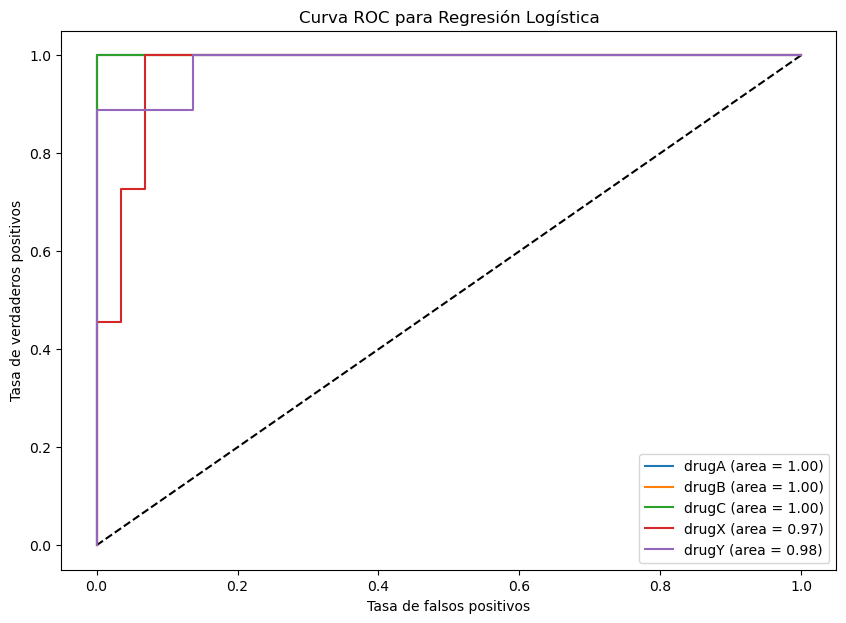

In [23]:
# Graficamos las curvas ROC del modelo seleccionado
# Cada curva representa una clase frente a las demás

plt.figure(figsize=(10,7))

plt.plot([0,1], [0,1], 'k--')

for i in range(len(model.classes_)):

    nombre = le_drug.inverse_transform([model.classes_[i]])[0]

    plt.plot(
        fpr[i], tpr[i],
        label = "%s (area = %0.2f)" % (nombre, auc[i])
    )

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend(loc = "lower right")
plt.title("Curva ROC para Regresión Logística")
plt.show()

In [24]:
# Calculamos el AUC global del modelo de clasificación
# Utilizamos el método One-vs-Rest para las distintas clases

auc_global = roc_auc_score(
    y_test,
    y_pred_probs,
    multi_class="ovr",
    average="macro",
    labels=model.classes_
)

print("AUC global:", auc_global)

AUC global: 0.9913270637408569


### Inciso 1. Transformación de variables cualitativas

Primero cargamos la base de datos Drugs, que contiene 200 observaciones y cinco variables predictoras.

Utilizamos la función `preprocessing.LabelEncoder()` para convertir las variables cualitativas Sex, BP y Cholesterol a valores numéricos. También transformamos la variable Drug, que es la que queremos predecir.

De esta manera, preparamos los datos para aplicar el modelo de regresión logística.

### Inciso 2. Comparación de métodos de optimización

Aplicamos cuatro métodos de optimización: sag, newton-cg, saga y lbfgs.

Al comparar los resultados, encontramos que los cuatro métodos obtuvieron una precisión global del **92.5 %** y un F1-score macro de **0.92619**.

Como todos presentaron el mismo desempeño, decidimos utilizar **sag**, ya que fue el primer método seleccionado por nuestro código y obtuvo resultados equivalentes a los demás.

### Inciso 3. Eficacia del modelo seleccionado

El modelo de regresión logística utilizando el método **sag** obtuvo una precisión global del **92.5 %**, lo que significa que clasificó correctamente 37 de las 40 observaciones utilizadas para la prueba.

Al revisar el reporte de clasificación, encontramos que el modelo identificó correctamente todos los casos de drugA, drugB y drugX. Sin embargo, presentó algunas dificultades para identificar drugC y drugY.

El F1-score fue de 1.00 para drugA y drugB, 0.80 para drugC, 0.92 para drugX y 0.91 para drugY.

También analizamos las curvas ROC y obtuvimos un **AUC global de aproximadamente 0.9913**, lo que indica que el modelo tiene una excelente capacidad para distinguir entre los diferentes tipos de medicamentos.

**Conclusión:** Consideramos que el modelo sag tuvo un buen desempeño, ya que logró una precisión elevada y una buena capacidad de clasificación. Aunque presentó algunos errores, sus resultados fueron satisfactorios para esta actividad.